Practical NO.01(A)    
Name - Sakshi Vijaykumar Muthiyan    
Roll No. -    
Title - To use PCA Algorithm for dimensionality reduction. You have a dataset that includes measurements for different variables on wine (alcohol, ash, magnesium, and so on). Apply PCA algorithm & transform this data so that most variations in the measurements of the variables are captured by a small number of principal components so that it is easier to distinguish between red and white wine by inspecting these principal components. 
Dataset Link: https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv 

In [2]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
print("All standard libraries imported successfully.")

All standard libraries imported successfully.


In [6]:
# The URL must be passed as a variable or wrapped inside quotes ""
url = "https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv"
print("Downloading the official manual dataset from the internet...")
df = pd.read_csv(url)
print(f"Dataset successfully loaded into memory! Shape: {df.shape}")
df.head(5)

Dataset successfully loaded into memory! Shape: (178, 14)


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [7]:
# Prints unique segments and missing entry analysis as requested on Page 10 of the manual
print("Unique Customer Segments available:")
print(df['Customer_Segment'].unique())
print("\nMissing values check per column:")
print(df.isnull().sum())

Unique Customer Segments available:
[1 2 3]

Missing values check per column:
Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64


In [8]:
# Splits attributes and scales each parameter according to the manual formula
X = df.drop('Customer_Segment', axis=1) 
y = df['Customer_Segment'] 
for col in X.columns:
    sc = StandardScaler() 
    X[col] = sc.fit_transform(X[[col]]) 
print("Features scaled and standard scores computed successfully.")
X.head(5)

Features scaled and standard scores computed successfully.


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


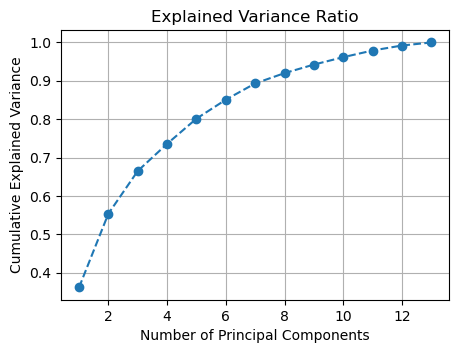

In [11]:
# Creates the mathematical step to figure out variance profile across components
pca = PCA()
X_pca = pca.fit_transform(X)
explained_variance_ratio = pca.explained_variance_ratio_
plt.figure(figsize=(5,3.5))
plt.plot(range(1, len(explained_variance_ratio) + 1), explained_variance_ratio.cumsum(), marker='o', linestyle='--')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance Ratio')
plt.grid(True)
plt.show()

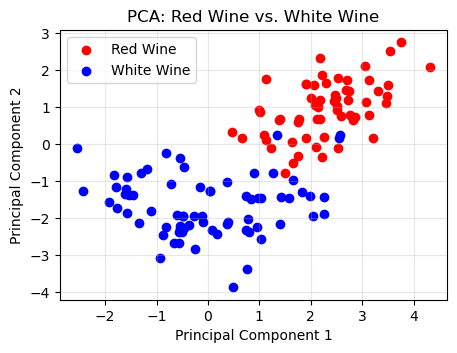

In [12]:
# Final evaluation component mapping and spatial sorting plot
n_components = 13 
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X)
red_indices = y[y == 1].index
white_indices = y[y == 2].index
plt.figure(figsize=(5,3.5))
plt.scatter(X_pca[red_indices, 0], X_pca[red_indices, 1], c='red', label='Red Wine')
plt.scatter(X_pca[white_indices, 0], X_pca[white_indices, 1], c='blue', label='White Wine')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.title('PCA: Red Wine vs. White Wine')
plt.grid(True, alpha=0.3)
plt.show()